# E8 · Is the assistant accurate and grounded? (live session)

PLAN §9, E8. Baseline: a keyword router. Stream C owns it. Parts:

1. **Intent accuracy** on the labelled questions (`data/e8_questions.yaml`), package classifier vs a keyword baseline.
2. **Grounded answers**: run the real pipeline (`anchorai.assistant.service.answer`) on a subset. *Calls the LLM.*
3. **Faithfulness**: cheap programmatic checks, then an LLM-as-judge. *Calls the LLM.*
4. **Latency**.
5. **Manual spot check** template.
6. **Ollama vs hosted** (only if a second endpoint is configured).

**Cost.** Parts 1 and 4's classifier timing run offline (local embeddings). Parts 2, 3 and 6 call the configured
endpoint: about `N` answer calls plus `N` judge calls (default `N = 20`), plus the same again for each calibration
case. Set `N` in the first cell. The base URL and key are never printed here.

**Caveats to quote with the numbers.**

- The ~60 questions were written by an AI (Claude) from the intent descriptions, and the training examples in
  `intents.yaml` have the same authors, so intent accuracy is **optimistic**. Streams A and B owe ~10 questions each
  (HANDOFFS #14, #15): append them to `data/e8_questions.yaml` (`stream_a_questions`, `stream_b_questions`); the accuracy
  table reports each author separately and the A/B numbers are the ones to trust.
- An LLM judging answers is itself fallible and tends to favour its own wording. The judge here is calibrated on two known
  bad answers and checked by hand in part 5, and by default it is the same model that wrote the answer; set `JUDGE_MODEL`
  to a different one if you can.
- The evidence comes from the scenario-layer data, so "faithful" means *faithful to the evidence lines*, not *true of a
  real gym*.

In [1]:
import json
import os
import re
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG, RES, DATA = Path("figures"), Path("results"), Path("data")
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

N = 20                      # answers to generate and judge (parts 2-6)
SEED = 0
JUDGE_MODEL = None          # None: the configured LLM_MODEL

from anchorai.config import get_settings

settings = get_settings()
print("endpoint:", "set" if settings.llm_base_url else "(not set)", "| model:", settings.llm_model,
      "| key:", "set" if settings.llm_api_key else "(not set)")

spec = yaml.safe_load((DATA / "e8_questions.yaml").read_text())
rows = [dict(q, group=g) for g in ("questions", "stream_a_questions", "stream_b_questions") for q in spec[g]]
qs = pd.DataFrame(rows)


def ctx(value):
    # pandas turns a missing context into NaN, which is truthy; the classifier wants None.
    return value if isinstance(value, str) else None


print(len(qs), "questions;", qs["author"].value_counts().to_dict())
qs["intent"].value_counts().to_frame("questions").T

endpoint: set | model: claude-haiku-5-5 | key: set
62 questions; {'ai': 62}


intent,member_risk,member_actions,unknown,graph_impact,list_members,compare_members,plan_summary,what_if_budget
questions,9,9,9,8,8,7,6,6


## 1. Intent accuracy

The package classifier (`get_classifier()`: sentence-embedding similarity to each intent's example centroid, a threshold
for `unknown`, and the member-slot rule) against a **keyword router** you can read in the next cell. The keyword router
gets the same slot extraction (member ids, amounts) so the comparison is about the intent decision.

In [2]:
from anchorai.assistant.classifier import UNKNOWN, get_classifier

t = time.perf_counter()
classifier = get_classifier()
print(f"classifier ready in {time.perf_counter() - t:.1f}s; intents:", [s.name for s in classifier.specs], "| threshold", classifier.threshold)
from anchorai.assistant.slots import extract_slots

INTENTS = [s.name for s in classifier.specs] + [UNKNOWN]
missing = sorted(set(qs["intent"]) - set(INTENTS))
if missing:
    print("WARNING: intents in the question set that the classifier does not know:", missing, "(they count as errors)")


def keyword_router(text, context_member_id=None):
    slots = extract_slots(text, classifier.instructors, classifier.classes)[0]
    n = len(slots.member_ids) or (1 if context_member_id else 0)
    t = text.lower()
    has = lambda *words: any(re.search(rf"\b{w}", t) for w in words)
    if has("budget", "spend", "what if") or slots.amount is not None:
        return "what_if_budget"
    if n >= 2 or (n == 1 and has("compare", "versus", "vs", "instead", "ahead")):
        return "compare_members"
    if slots.instructor_ids or slots.class_ids or has("affected", "instructor", "cancel", "cancelled"):
        return "graph_impact" if not n else "member_actions"
    if has("plan"):
        return "plan_summary"
    if n == 1:
        return "member_actions" if has("offer", "should", "do", "rule", "contact", "recommend", "action") else "member_risk"
    if has("top", "list", "most", "rank", "riskiest", "at risk", "high risk"):
        return "list_members"
    return UNKNOWN

Loading weights: 100%|██████████████████████████████████████████████████████████████████| 103/103 [00:00<00:00, 35117.32it/s]


classifier ready in 5.7s; intents: ['member_risk', 'member_actions', 'compare_members', 'graph_impact', 'list_members', 'plan_summary', 'what_if_budget'] | threshold 0.35


In [3]:
preds, lat = [], []
for q in qs.itertuples():
    t = time.perf_counter()
    p = classifier.classify(q.question, ctx(q.context_member_id))
    lat.append(time.perf_counter() - t)
    preds.append({"pred": p.intent, "score": p.score, "baseline": keyword_router(q.question, ctx(q.context_member_id))})
qs = qs.drop(columns=[c for c in ("pred", "score", "baseline") if c in qs]).join(pd.DataFrame(preds))
qs["correct"] = qs["pred"] == qs["intent"]
qs["baseline_correct"] = qs["baseline"] == qs["intent"]
print(f"classifier accuracy {qs['correct'].mean():.1%} | keyword baseline {qs['baseline_correct'].mean():.1%} | "
      f"classify latency median {np.median(lat) * 1000:.0f} ms, p95 {np.percentile(lat, 95) * 1000:.0f} ms")
qs.groupby("author")[["correct", "baseline_correct"]].agg(["mean", "size"]).round(3)

classifier accuracy 90.3% | keyword baseline 77.4% | classify latency median 1 ms, p95 2 ms


correct      baseline_correct     
          mean size             mean size
author                                   
ai       0.903   62            0.774   62

In [4]:
from sklearn.metrics import classification_report, confusion_matrix

report = pd.DataFrame(classification_report(qs["intent"], qs["pred"], labels=INTENTS, output_dict=True, zero_division=0)).T
report_b = pd.DataFrame(classification_report(qs["intent"], qs["baseline"], labels=INTENTS, output_dict=True, zero_division=0)).T
per_intent = report.join(report_b, lsuffix="_classifier", rsuffix="_keyword")[
    ["precision_classifier", "recall_classifier", "f1-score_classifier", "f1-score_keyword", "support_classifier"]]
per_intent.round(2).to_csv(RES / "e8_intent_report.csv")
per_intent.round(2)

,precision_classifier,recall_classifier,f1-score_classifier,f1-score_keyword,support_classifier
member_risk,1.00,0.89,0.94,0.74,9.0
member_actions,1.00,0.89,0.94,0.75,9.0
compare_members,1.00,1.00,1.00,1.00,7.0
graph_impact,0.88,0.88,0.88,0.82,8.0
list_members,0.80,1.00,0.89,0.67,8.0
plan_summary,1.00,0.67,0.80,0.80,6.0
what_if_budget,0.86,1.00,0.92,0.92,6.0
unknown,0.80,0.89,0.84,0.61,9.0
accuracy,0.90,0.90,0.90,0.77,0.9
macro avg,0.92,0.90,0.90,0.79,62.0


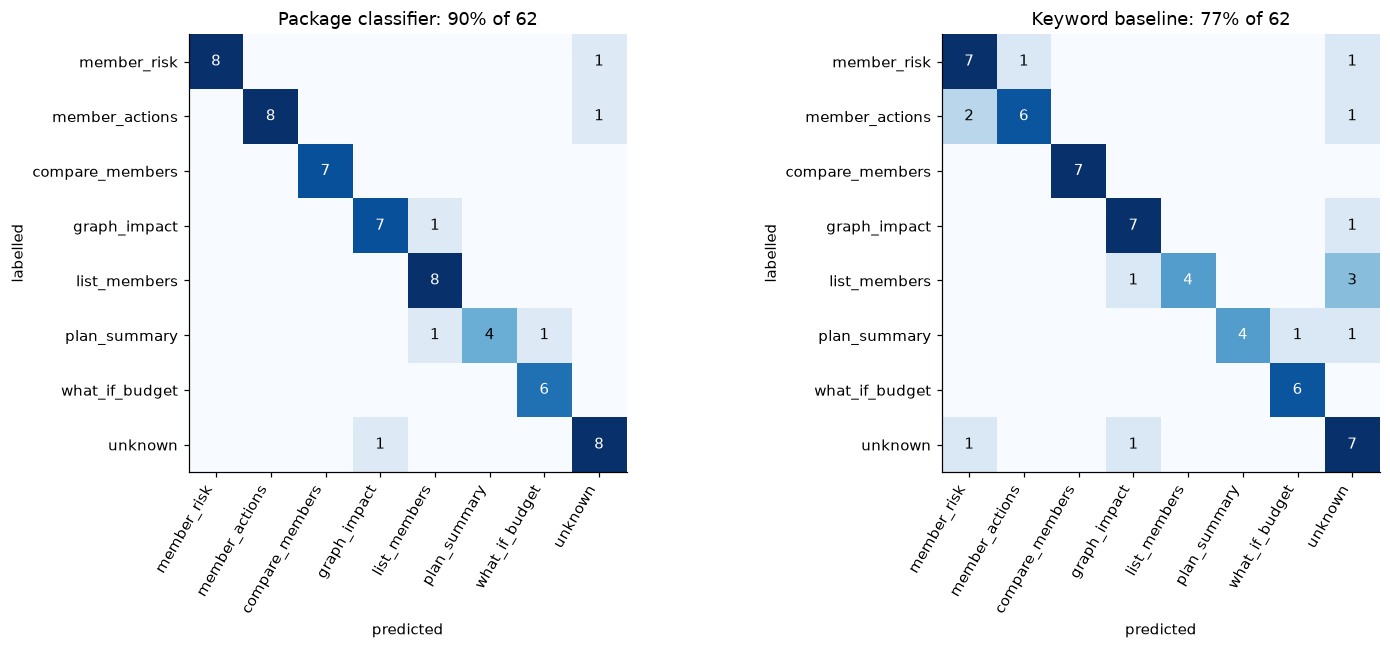

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, col, title in zip(axes, ["pred", "baseline"], ["Package classifier", "Keyword baseline"]):
    cm = confusion_matrix(qs["intent"], qs[col], labels=INTENTS)
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(INTENTS)), INTENTS, rotation=60, ha="right")
    ax.set_yticks(range(len(INTENTS)), INTENTS)
    for i in range(len(INTENTS)):
        for j in range(len(INTENTS)):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xlabel("predicted")
    ax.set_ylabel("labelled")
    ax.set_title(f"{title}: {(qs['intent'] == qs[col]).mean():.0%} of {len(qs)}")
fig.tight_layout()
fig.savefig(FIG / "e8_intent_confusion.png", bbox_inches="tight")

**Look at the errors.** Which are real classifier mistakes, which are ambiguous labels (the `notes` column flags boundary cases)?

In [6]:
errors = qs.loc[~qs["correct"], ["id", "question", "intent", "pred", "score", "baseline", "notes", "author"]]
errors.to_csv(RES / "e8_intent_errors.csv", index=False)
qs[["id", "author", "question", "intent", "pred", "score", "baseline", "correct", "baseline_correct"]].to_csv(RES / "e8_intent_predictions.csv", index=False)
errors

,id,question,intent,pred,score,baseline,notes,author
5,q06,how worried should we be about 1288?,member_risk,unknown,0.2553,unknown,"bare number, vague wording",ai
16,q17,Show the playbook for 1999,member_actions,unknown,0.1590,unknown,NaN,ai
30,q31,anyone hurt by the recent staff departure?,graph_impact,list_members,0.3710,unknown,no entity named,ai
42,q43,how much are we spending this week,plan_summary,what_if_budget,0.5334,what_if_budget,NaN,ai
44,q45,Which members are we ringing this week?,plan_summary,list_members,0.5738,unknown,boundary with list_members; plan call list,ai
58,q59,How do I add a new instructor?,unknown,graph_impact,0.5191,graph_impact,"app how-to, no tool",ai


### Threshold sensitivity

The `unknown` decision is a single similarity threshold. Re-classify with the threshold off, then sweep it: too low
answers off-topic questions, too high refuses in-scope ones. (Same-author caveat applies: the threshold was tuned on the
training examples, not on this set.)

,threshold,accuracy,in_scope_refused,off_topic_answered
0,0.150,0.855,0.000,0.444
1,0.175,0.855,0.019,0.444
2,0.200,0.855,0.019,0.444
3,0.225,0.855,0.019,0.444
4,0.250,0.887,0.019,0.222
5,0.275,0.887,0.038,0.222
6,0.300,0.887,0.038,0.222
7,0.325,0.903,0.038,0.111
8,0.350,0.903,0.038,0.111
9,0.375,0.903,0.057,0.111


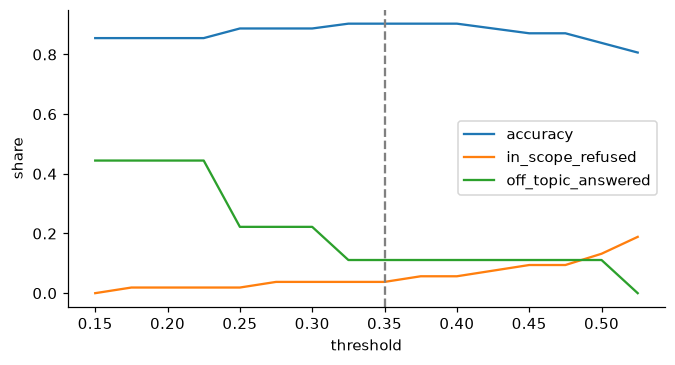

In [7]:
classifier.threshold, saved = -1.0, classifier.threshold
raw = [classifier.classify(q.question, ctx(q.context_member_id)) for q in qs.itertuples()]
classifier.threshold = saved
sweep = []
for th in np.arange(0.15, 0.55, 0.025):
    guess = [p.intent if p.score >= th else UNKNOWN for p in raw]
    truth = qs["intent"]
    sweep.append({
        "threshold": round(th, 3),
        "accuracy": float(np.mean([g == t for g, t in zip(guess, truth)])),
        "in_scope_refused": float(np.mean([g == UNKNOWN for g, t in zip(guess, truth) if t != UNKNOWN])),
        "off_topic_answered": float(np.mean([g != UNKNOWN for g, t in zip(guess, truth) if t == UNKNOWN])),
    })
sweep = pd.DataFrame(sweep)
sweep.round(3).to_csv(RES / "e8_threshold_sweep.csv", index=False)
ax = sweep.set_index("threshold").plot(figsize=(7, 3.5))
ax.axvline(saved, color="grey", ls="--")
ax.set_ylabel("share")
ax.figure.savefig(FIG / "e8_threshold_sweep.png", bbox_inches="tight")
sweep.round(3)

## 2. Grounded answers  (calls the LLM)

A stratified sample of `N` questions goes through the **real** pipeline: classifier, slots, deterministic tool,
grounded prompt, LLM. The session reads the app DB (plan, rosters) and writes nothing. Each answer keeps its evidence
lines so the judge can check against them. `role="manager"` so plan questions are answered.

**Look for:** `grounded=False` answers should be the "I don't know" / note replies; `llm_used=False` means the LLM
failed and the template fallback answered (those are skipped by the judge).

In [8]:
from sqlmodel import Session

from anchorai.assistant import llm
from anchorai.assistant.service import answer
from anchorai.db.session import get_engine

sample = pd.concat([
    qs[qs["intent"] == name].sample(min(n_in, max(1, round(N * n_in / len(qs)))), random_state=SEED)
    for name, n_in in qs["intent"].value_counts().items()
]).head(N)
print(len(sample), "questions:", sample["intent"].value_counts().to_dict())

llm_seconds = []


def timed_chat(messages):
    t = time.perf_counter()
    try:
        return llm.chat(messages)
    finally:
        llm_seconds.append(time.perf_counter() - t)


results = []
with Session(get_engine()) as session:
    for q in sample.itertuples():
        llm_seconds.clear()
        t = time.perf_counter()
        try:
            r = answer(session, q.question, ctx(q.context_member_id), role="manager", classifier=classifier, chat=timed_chat)
        except Exception as e:  # keep going: one failure should not lose the run
            results.append({"id": q.id, "error": type(e).__name__})
            continue
        results.append({
            "id": q.id, "question": q.question, "labelled": q.intent, "intent": r.intent, "tool": r.tool,
            "grounded": r.grounded, "llm_used": r.llm_used, "answer": r.answer,
            "evidence": json.dumps([e.model_dump() for e in r.evidence]),
            "total_s": time.perf_counter() - t, "llm_s": sum(llm_seconds),
        })
answers = pd.DataFrame(results)
answers.to_csv(RES / "e8_answers.csv", index=False)
print(answers[["grounded", "llm_used"]].value_counts().to_dict(), "| errors:", int(answers.get("error", pd.Series(dtype=object)).notna().sum()))
answers[["id", "question", "intent", "grounded", "llm_used", "answer"]]

20 questions: {'member_risk': 3, 'member_actions': 3, 'unknown': 3, 'graph_impact': 3, 'list_members': 3, 'compare_members': 2, 'plan_summary': 2, 'what_if_budget': 1}
{(True, True): 13, (False, False): 7} | errors: 0


,id,question,intent,grounded,llm_used,answer
0,q08,Which signals suggest member 2999 is slipping ...,member_risk,True,True,The data shows little sign that member 2999 is...
1,q03,M0231 churn risk breakdown please,member_risk,True,True,"M0231 has a 1% churn probability, which is low..."
2,q02,whats the chance that member 77 cancels their ...,member_risk,True,True,"Member 77's churn probability is 2%, which is ..."
3,q17,Show the playbook for 1999,unknown,False,False,I don't know based on the data I have.
4,q12,What did the rules decide for member 2040?,member_actions,True,True,The rules blocked every offer for member 2040....
5,q11,can we send M0066 a discount?,member_actions,True,True,"No, the discount is blocked. ""One month at 20%..."
6,q61,Which machine should I use for legs?,unknown,False,False,I don't know based on the data I have.
7,q56,What does churn mean?,unknown,False,False,I don't know based on the data I have.
8,q55,What time does the pool close on Sundays?,unknown,False,False,I don't know based on the data I have.
9,q32,whos affected by nora ali leaving,graph_impact,True,True,Nora Ali's classes are attended by 272 members...


## 3. Faithfulness

### 3a. Programmatic checks (free)

For each LLM answer: every sentence cites at least one evidence id; every cited id exists in the evidence; every number
or member id in the answer appears in the evidence. These catch invented figures and dangling citations; they cannot catch
an unsupported *reason* (that is what the judge is for).

In [19]:
CITE = re.compile(r"\[(E\d+)\]")
NUMBER = re.compile(r"M\d{4}|[<>]?\d+(?:[.,]\d+)*%?")


def norm(n):
    # "M0077", "member 77" and "4,000" vs "4000" are the same figure.
    n = n.lstrip("<>M").replace(",", "")
    return str(int(n)) if n.isdigit() else n


def split_sentences(text):
    parts = re.split(r"\n+|(?<=[.!?])\s+(?=[A-Z\[])", text.strip())
    return [p.strip(" -\u2022") for p in parts if p.strip(" -\u2022")]


def static_checks(answer_text, evidence):
    ids = {e["id"] for e in evidence}
    evidence_text = " ".join(e["text"] for e in evidence)
    cited = CITE.findall(answer_text)
    plain = CITE.sub("", answer_text)
    sentences = split_sentences(answer_text)
    nums = {norm(n) for n in NUMBER.findall(plain)}
    known = {norm(n) for n in NUMBER.findall(evidence_text)}
    return {
        "sentences": len(sentences),
        # A lead-in ending in ":" introduces a cited list, so it needs no citation of its own.
        "uncited_sentences": sum(not CITE.search(s) and not s.endswith(":") for s in sentences),
        "dangling_citations": sorted(set(cited) - ids),
        "numbers_not_in_evidence": sorted(nums - known),
    }


llm_answers = answers[answers.get("llm_used", False) == True].copy()  # noqa: E712
checks = pd.DataFrame([static_checks(r.answer, json.loads(r.evidence)) for r in llm_answers.itertuples()], index=llm_answers["id"])
checks["ok"] = (checks["uncited_sentences"] == 0) & (checks["dangling_citations"].str.len() == 0) & (checks["numbers_not_in_evidence"].str.len() == 0)
checks.to_csv(RES / "e8_static_checks.csv")
print(f"{checks['ok'].mean():.0%} of {len(checks)} LLM answers pass all three checks")
checks

62% of 13 LLM answers pass all three checks


,sentences,uncited_sentences,dangling_citations,numbers_not_in_evidence,ok
id,,,,,
q08,6,1,[],[],False
q03,8,2,[],[],False
q02,3,0,[],[],True
q12,4,1,[],[],False
q11,2,0,[],[],True
q32,7,0,[],[],True
q28,2,0,[],[],True
q27,8,0,[],[],True
q40,12,0,[],[],True


### 3b. LLM-as-judge

The judge sees only the evidence lines and the answer (not the question's intent or how the answer was made), splits the
answer into sentences and labels each **supported / unsupported / contradicted**. The prompt is deliberately strict:
reasons, advice and ordering that the evidence does not state are *unsupported*, and a claim that data is missing when an
evidence line shows it is *contradicted*.

**First, calibrate on the two known problem answers** (`faithfulness_cases` in the question file), written from real
failures: the discount answer that invented "needs month-to-month terms, which the data doesn't show", and the
"Start with the check-in..." ordering. The judge must flag each *bad* answer and pass each *good* one before you trust it on
the sample. (This is 4 judge calls.)

In [20]:
from anchorai.assistant.llm import get_client

JUDGE_SYSTEM = (
    "You audit an assistant's answer against its evidence. Split the answer into sentences or bullets. "
    "For each, give a label:\n"
    "- supported: every claim is stated in an evidence line or follows from one directly;\n"
    "- unsupported: it contains a claim, number, name, reason, recommendation or ordering that no evidence line states;\n"
    "- contradicted: it conflicts with an evidence line, including saying data is missing that an evidence line shows.\n"
    "Be strict: reasons, causes, advice and what to do first are unsupported unless an evidence line says so. "
    "The reply 'I don't know based on the data I have.' is supported. "
    "Also list the evidence ids the sentence cites and whether those lines really support it.\n"
    'Reply with JSON only: {"sentences": [{"text": "...", "label": "supported|unsupported|contradicted", '
    '"cited": ["E1"], "citations_ok": true, "reason": "under 15 words"}]}'
)


def judge(answer_text, evidence_lines, model=None):
    user = "Evidence:\n" + "\n".join(evidence_lines) + "\n\nAnswer:\n" + answer_text
    reply = get_client().chat.completions.create(
        model=model or JUDGE_MODEL or settings.llm_model, temperature=0,
        messages=[{"role": "system", "content": JUDGE_SYSTEM}, {"role": "user", "content": user}],
    ).choices[0].message.content or ""
    reply = re.sub(r"^```(?:json)?|```$", "", reply.strip(), flags=re.MULTILINE).strip()
    try:
        return json.loads(reply)["sentences"]
    except (json.JSONDecodeError, KeyError, TypeError):
        return [{"text": reply[:200], "label": "judge_parse_error", "cited": [], "citations_ok": False, "reason": "unparseable judge reply"}]


def evidence_lines(evidence):
    return [f"[{e['id']}] {e['text']}" for e in evidence]

In [11]:
calibration = []
for case in spec["faithfulness_cases"]:
    for kind in ("bad_answer", "good_answer"):
        verdict = judge(case[kind], case["evidence"])
        calibration.append({"case": case["id"], "answer": kind, **{k: sum(s["label"] == k for s in verdict) for k in ("supported", "unsupported", "contradicted")},
                            "flagged": [s["text"][:70] for s in verdict if s["label"] != "supported"]})
        print(case["id"], kind, "| static:", static_checks(case[kind], [{"id": l[1:3], "text": l} for l in case["evidence"]]))
calibration = pd.DataFrame(calibration)
calibration.to_csv(RES / "e8_judge_calibration.csv", index=False)
calibration

f01 bad_answer | static: {'sentences': 1, 'uncited_sentences': 0, 'dangling_citations': [], 'numbers_not_in_evidence': []}
f01 good_answer | static: {'sentences': 3, 'uncited_sentences': 0, 'dangling_citations': [], 'numbers_not_in_evidence': []}
f02 bad_answer | static: {'sentences': 1, 'uncited_sentences': 0, 'dangling_citations': [], 'numbers_not_in_evidence': []}
f02 good_answer | static: {'sentences': 1, 'uncited_sentences': 0, 'dangling_citations': [], 'numbers_not_in_evidence': []}


,case,answer,supported,unsupported,contradicted,flagged
0,f01,bad_answer,0,1,0,[The discounted month is blocked by G03 becaus...
1,f01,good_answer,2,1,0,[A free PT session by call is allowed instead ...
2,f02,bad_answer,0,1,0,[Start with the check-in message by SMS to reb...
3,f02,good_answer,1,0,0,[]


**Expected:** both `bad_answer` rows flag at least one sentence (`unsupported`/`contradicted`); both `good_answer` rows flag
none. If not, tighten `JUDGE_SYSTEM` before going on. Note what the case file says the judge should catch (`expect_bad`).

In [21]:
verdicts = []
for r in llm_answers.itertuples():
    for s in judge(r.answer, evidence_lines(json.loads(r.evidence))):
        verdicts.append({"id": r.id, "intent": r.intent, "sentence": s["text"], "label": s["label"],
                         "citations_ok": s.get("citations_ok"), "reason": s.get("reason", "")})
verdicts = pd.DataFrame(verdicts)
verdicts.to_csv(RES / "e8_judge_sentences.csv", index=False)

per_answer = verdicts.groupby("id").agg(
    sentences=("label", "size"), supported=("label", lambda s: (s == "supported").sum()),
    flagged=("label", lambda s: (s != "supported").sum()))
per_answer["fully_supported"] = per_answer["flagged"] == 0
faith = pd.DataFrame({
    "sentences": [len(verdicts)],
    "supported_share": [(verdicts["label"] == "supported").mean()],
    "unsupported_share": [(verdicts["label"] == "unsupported").mean()],
    "contradicted_share": [(verdicts["label"] == "contradicted").mean()],
    "answers": [len(per_answer)],
    "fully_supported_answers": [per_answer["fully_supported"].mean()],
    "citations_ok_share": [verdicts["citations_ok"].astype(bool).mean()],
}).round(3)
faith.to_csv(RES / "e8_faithfulness.csv", index=False)
faith

,sentences,supported_share,unsupported_share,contradicted_share,answers,fully_supported_answers,citations_ok_share
0,94,0.968,0.032,0.0,13,0.769,0.979


In [22]:
verdicts[verdicts["label"] != "supported"][["id", "intent", "label", "sentence", "reason"]]

,id,intent,label,sentence,reason
13,q03,member_risk,unsupported,The visit-trend label may need checking [E2][E5].,"The cited lines show a conflict, but the recom..."
33,q27,graph_impact,unsupported,The 298 members who attend Ana Costa's classes...,E1 gives the 298 count but never says the memb...
41,q40,list_members,unsupported,"All 10 members shown are high risk, with churn...","E2-E11 support the >99% risk, but no line says..."


,mean,size
intent,,
compare_members,1.00,18
graph_impact,0.94,17
list_members,0.97,35
member_actions,1.00,7
member_risk,0.94,17


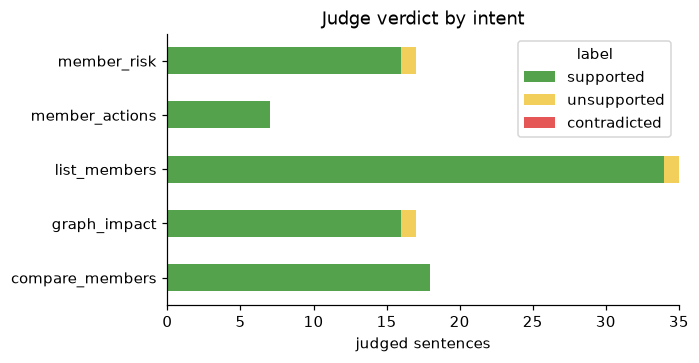

In [23]:
by_intent = verdicts.assign(ok=verdicts["label"] == "supported").groupby("intent")["ok"].agg(["mean", "size"]).round(2)
fig, ax = plt.subplots(figsize=(6, 3.2))
counts = verdicts.groupby(["intent", "label"]).size().unstack(fill_value=0).reindex(columns=["supported", "unsupported", "contradicted"], fill_value=0)
counts.plot.barh(stacked=True, ax=ax, color=["#54a24b", "#f2cf5b", "#e45756"])
ax.set_xlabel("judged sentences")
ax.set_ylabel("")
ax.set_title("Judge verdict by intent")
fig.savefig(FIG / "e8_faithfulness.png", bbox_inches="tight")
by_intent

## 4. Latency

End-to-end per question (classify + tool + LLM) and the LLM call alone. Template and note replies (no LLM) are in the
first number only. Local model on a laptop and a hosted API will differ widely; say which one produced these.

,n,median_s,p95_s,max_s
end-to-end,20,3.38,5.56,8.81
LLM call only,13,3.84,6.75,8.80


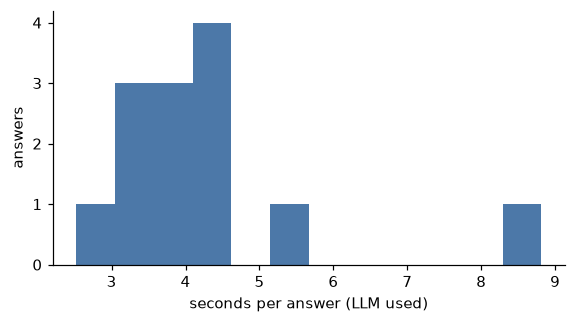

In [15]:
lat = answers.dropna(subset=["total_s"])
latency = pd.DataFrame({
    "n": [len(lat), int(lat["llm_used"].sum())],
    "median_s": [lat["total_s"].median(), lat.loc[lat["llm_used"], "llm_s"].median()],
    "p95_s": [lat["total_s"].quantile(0.95), lat.loc[lat["llm_used"], "llm_s"].quantile(0.95)],
    "max_s": [lat["total_s"].max(), lat.loc[lat["llm_used"], "llm_s"].max()],
}, index=["end-to-end", "LLM call only"]).round(2)
latency.to_csv(RES / "e8_latency.csv")
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(lat.loc[lat["llm_used"], "total_s"], bins=12, color="#4c78a8")
ax.set_xlabel("seconds per answer (LLM used)")
ax.set_ylabel("answers")
fig.savefig(FIG / "e8_latency.png", bbox_inches="tight")
latency

## 5. Manual spot check

The judge is a model; a human has the last word. Reads 15 sampled answers beside their evidence, fills the empty columns
in `results/e8_spot_check.csv` (open it in a spreadsheet), then the last cell summarises. Two people should each fill one
column set if possible; agree on disagreements.

- `faithful`: y / n (every claim backed by the evidence lines?)
- `correct`: y / n (does it answer what was asked?)
- `useful`: 1-5
- `judge_agrees`: y / n (compare with `judge_flagged`)
- `notes`

In [16]:
flagged = verdicts[verdicts["label"] != "supported"].groupby("id").size()
spot = llm_answers.sample(min(15, len(llm_answers)), random_state=SEED)[["id", "question", "answer", "evidence"]].copy()
spot["evidence"] = spot["evidence"].map(lambda e: " | ".join(f"[{x['id']}] {x['text']}" for x in json.loads(e)))
spot["judge_flagged"] = spot["id"].map(flagged).fillna(0).astype(int)
for col in ("faithful", "correct", "useful", "judge_agrees", "notes"):
    spot[col] = ""
path = RES / "e8_spot_check.csv"
if path.exists() and pd.read_csv(path)["faithful"].notna().any():
    print("existing spot-check file has entries; not overwriting")
else:
    spot.to_csv(path, index=False)
    print("template written to", path)

template written to results/e8_spot_check.csv


In [17]:
filled = pd.read_csv(RES / "e8_spot_check.csv")
done = filled[filled["faithful"].isin(["y", "n"])]
if done.empty:
    print("nothing filled in yet")
else:
    print(f"{len(done)} checked | faithful {done['faithful'].eq('y').mean():.0%} | correct {done['correct'].eq('y').mean():.0%} | "
          f"mean usefulness {pd.to_numeric(done['useful'], errors='coerce').mean():.1f} | judge agrees {done['judge_agrees'].eq('y').mean():.0%}")

nothing filled in yet


## 6. Ollama vs hosted model

Runs only when a **second** OpenAI-compatible endpoint is configured through the environment (not committed):

```
E8_ALT_BASE_URL=...   E8_ALT_API_KEY=...   E8_ALT_MODEL=...
```

It replays the *same evidence* from part 2 through the alternative model with the package's grounded prompt
(`anchorai.assistant.prompt.build_messages`), then judges both sets with the same judge, and compares latency and
faithfulness. The model configured in `.env` is "primary" (say in the report which of Ollama/hosted that is).
Evidence is held fixed so only the phrasing model differs.

In [18]:
from openai import OpenAI

from anchorai.assistant.prompt import build_messages
from anchorai.assistant.tools import Evidence

alt = {k: os.environ.get(f"E8_ALT_{k}") for k in ("BASE_URL", "API_KEY", "MODEL")}
if not all(alt.values()):
    print("No alternative endpoint configured (set E8_ALT_BASE_URL, E8_ALT_API_KEY, E8_ALT_MODEL); skipping part 6.")
else:
    alt_client = OpenAI(base_url=alt["BASE_URL"], api_key=alt["API_KEY"], timeout=settings.llm_timeout_seconds, max_retries=1)
    alt_rows = []
    for r in llm_answers.itertuples():
        evid = [Evidence(**e) for e in json.loads(r.evidence)]
        t = time.perf_counter()
        text = alt_client.chat.completions.create(
            model=alt["MODEL"], temperature=settings.llm_temperature, messages=build_messages(r.question, evid),
        ).choices[0].message.content or ""
        alt_rows.append({"id": r.id, "answer": text, "evidence": r.evidence, "llm_s": time.perf_counter() - t})
    alt_answers = pd.DataFrame(alt_rows)

    def summarise(frame, name, model):
        v = [s["label"] for r in frame.itertuples() for s in judge(r.answer, evidence_lines(json.loads(r.evidence)))]
        st = [static_checks(r.answer, json.loads(r.evidence)) for r in frame.itertuples()]
        return {"model": name, "answers": len(frame), "median_llm_s": frame["llm_s"].median(), "p95_llm_s": frame["llm_s"].quantile(0.95),
                "supported_share": np.mean([x == "supported" for x in v]),
                "static_ok": np.mean([not s["uncited_sentences"] and not s["dangling_citations"] and not s["numbers_not_in_evidence"] for s in st])}

    comparison = pd.DataFrame([
        summarise(llm_answers, f"primary ({settings.llm_model})", None),
        summarise(alt_answers, f"alternative ({alt['MODEL']})", None),
    ]).round(3)
    comparison.to_csv(RES / "e8_model_comparison.csv", index=False)
    print(comparison.to_string(index=False))

No alternative endpoint configured (set E8_ALT_BASE_URL, E8_ALT_API_KEY, E8_ALT_MODEL); skipping part 6.


## 7. Findings

From the run on 2026-10-16 (model `claude-haiku-5-5`, hosted). The spot check (part 5) was filled by Claude Code and
checked by the owner, so it is not an independent human rating.

1. **Intent accuracy: 90.3% vs 77.4%** for the keyword baseline on 62 questions (macro F1 0.90 vs 0.79). The six misses
   are boundary cases ("how much are we spending this week" read as a budget question, "which members are we ringing
   this week" as a member list, "anyone hurt by the recent staff departure" with no instructor named), one app how-to
   question answered as graph impact, and two bare-number questions: "how worried should we be about 1288?" scores below the threshold, and "Show the playbook for 1999" fails because a bare
   number from 1900 to 2099 is read as a year, not a member id. **Caveat:** all 62 questions are AI-written, and the
   threshold (0.35) was chosen after looking at this set, so 90.3% is optimistic. The Stream A and B questions
   (HANDOFFS #14, #15) are the held-out check.
2. **Threshold:** accuracy is flat (0.887-0.903) from 0.25 to 0.425. Below 0.25, 44% of off-topic questions get an
   answer; above 0.45, in-scope refusals climb past 9%.
3. **Grounding:** of 20 sampled questions, 13 went to the LLM. The other 7 got a fixed reply without an LLM call: the 3
   off-topic ones and the misrouted q17 got "I don't know", and 3 plan / what-if questions got "no plan yet" notes because
   Stream B's optimiser isn't connected. No answer used a number or member id missing from the evidence, and no citation pointed at a
   missing evidence line. 8 of 13 answers pass every static check; the other 5 have an opening or summary sentence
   whose citation only comes in the next sentence.
4. **Judge calibration:** the judge flagged both known bad answers (the invented "needs month-to-month terms" reason and
   the invented contact order). It also flagged "instead" in one good answer, so it is strict and its scores are a
   lower bound.
5. **Judge on the sample:** 96.8% of 94 sentences supported, 3.2% unsupported, none contradicted; 10 of 13 answers
   (76.9%) fully supported. The 3 flagged sentences are all small inferences, not invented facts: advice to check a
   driver label (q03), calling class attendees "affected" (q27), and saying a list "doesn't rank" members (q40). The
   judge is not stable at temperature 0: an earlier run of the same answers flagged q03 and q27 but not q40.
6. **Spot check (13 answers):** 11 faithful (85%), 13 answer the question, mean usefulness 3.9 / 5, and the judge agrees
   on 12 of 13. The disagreement is q27, where the judge was stricter than needed.
7. **Driver wording:** in all 3 member-risk answers the LLM pointed out that "Drop in weekly visits" is listed as a
   driver while visits are flat or rising. It is right: the label is a feature name, not an event. Rewording the driver
   label (e.g. "Change in weekly visits") would remove these comments.
8. **Latency:** median 3.4 s end to end (p95 5.6 s, max 8.8 s) over 20 questions; the LLM call is nearly all of it
   (median 3.8 s over the 13 that used it). Classification takes about 1 ms. Refusals are instant. A local Ollama model
   was not tested (part 6 skipped).
9. **Prompt changes suggested by the failures:** ask for a citation on every sentence, including the first, and tell the
   model not to add advice or comments about the data that the evidence lines do not state.
